# Week 11: Geocodes and Locations; Layering data on maps
## Name: Bria Pickel-Fridman
## 11/2/2026

### Week 11: Geocoding with OpenStreetMap
Geocoding means turning a description of a place ("Pratt Institute, Brooklyn" or "30 Lincoln Center Plaza") into coordinates: a latitude and a longitude. Once we have coordinates, we can put the place on a map, like the ones in Week 10.

OpenStreetMap (OSM) is a free, editable map of the world. Its geocoding service is called Nominatim, and it's an API like the Met API from Part 10: we send a request to a web address with some parameters, and it sends back JSON.

Rules for using it. Nominatim is run by volunteers on a few servers. As such, it's important to make note of their usage policy:

No more than one request per second. We'll use time.sleep(1).
Identify your program with a User-Agent header, as we did when scraping. Requests without one are blocked.
Don't geocode thousands of places this way. Save (cache) the results, and don't ask for the same place twice.
The data is provided and copyrighted by OpenStreetMap contributors. If you publish a map that uses it, I recommend that you attribute it.

class: week of november 23rd remote and 20 minute private session? schedule with prof.

In [2]:
import json
import time

import pandas as pd
import plotly.express as px
import requests

In [3]:
url = "https://nominatim.openstreetmap.org/search"

# an honest name for our program, as in Part 11. Nominatim blocks requests without one
headers = {"User-Agent": "INFO664-class-project (educational)"}

params = {"q": "Pratt Institute, Brooklyn", "format": "jsonv2", "limit": 1}

response = requests.get(url, params=params, headers=headers)

# check that the request worked (200 means OK), and look at the address that requests built
print(response.status_code)
print(response.url)

200
https://nominatim.openstreetmap.org/search?q=Pratt+Institute%2C+Brooklyn&format=jsonv2&limit=1


In [4]:
results = response.json()

print(len(results), "result")

# json.dumps() with indent prints a dictionary in a readable way
print(json.dumps(results[0], indent=2))

1 result
{
  "place_id": 359030172,
  "licence": "Data \u00a9 OpenStreetMap contributors, ODbL 1.0. http://osm.org/copyright",
  "osm_type": "relation",
  "osm_id": 4425764,
  "lat": "40.6913383",
  "lon": "-73.9630163",
  "category": "amenity",
  "type": "university",
  "place_rank": 30,
  "importance": 0.5429685502967774,
  "addresstype": "amenity",
  "name": "Pratt Institute",
  "display_name": "Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States",
  "boundingbox": [
    "40.6877108",
    "40.6945682",
    "-73.9682790",
    "-73.9604328"
  ]
}


In [5]:
place = results[0]

latitude = float(place["lat"])
longitude = float(place["lon"])

print(place["display_name"])
print(latitude, longitude)

Pratt Institute, 200, Willoughby Avenue, Clinton Hill, Brooklyn, Kings County, New York, 11205, United States
40.6913383 -73.9630163


In [6]:
def geocode(query):
    """Look up a place name or address. Return a dictionary with its coordinates, or None."""
    params = {"q": query, "format": "jsonv2", "limit": 1}
    response = requests.get(url, params=params, headers=headers)

    time.sleep(1)                  # be polite: no more than one request per second

    if not response.ok:            # for example, a 403 or 429 error
        print("request failed:", response.status_code, "for", query)
        return None

    results = response.json()

    if len(results) == 0:          # nothing matched
        print("no match for:", query)
        return None

    place = results[0]

    return {
        "query": query,
        "name": place["name"],
        "address": place["display_name"],
        "type": place["type"],
        "lat": float(place["lat"]),
        "lon": float(place["lon"]),
    }


geocode("Brooklyn Museum")

{'query': 'Brooklyn Museum',
 'name': 'Brooklyn Museum',
 'address': 'Brooklyn Museum, 200, Eastern Parkway, Brooklyn, Kings County, New York, 11238, United States',
 'type': 'museum',
 'lat': 40.6709546,
 'lon': -73.9632948}

In [7]:
queries = [
    "Pratt Institute, Brooklyn",
    "Brooklyn Museum",
    "Metropolitan Museum of Art, New York",
    "Cooper Hewitt, New York",
    "Guggenheim Museum, New York",
    "Whitney Museum of American Art",
    "qwertyuiop zxcvbnm nowhere",
]

places = []

for query in queries:
    result = geocode(query)

    if result is not None:
        places.append(result)

print(len(places), "of", len(queries), "found")

no match for: qwertyuiop zxcvbnm nowhere
6 of 7 found


In [8]:
table = pd.DataFrame(places)

table[["query", "name", "type", "lat", "lon"]]

,query,name,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,museum,40.782993,-73.958925
5,Whitney Museum of American Art,Whitney Museum of American Art,museum,40.739645,-74.008921


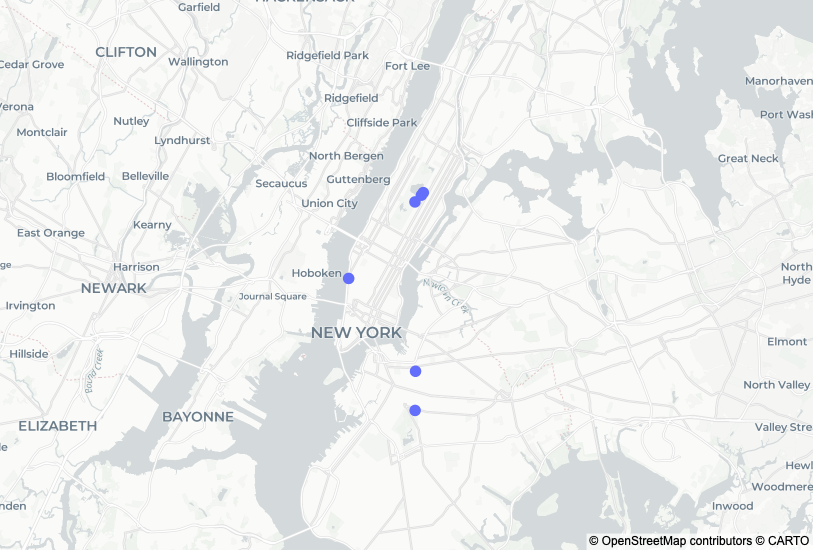

In [9]:
# the center of the map: the average latitude and the average longitude of our places
center = {"lat": table["lat"].mean(), "lon": table["lon"].mean()}

fig = px.scatter_map(
    table,
    lat="lat",                           # the columns with each place's coordinates
    lon="lon",
    hover_name="name",
    hover_data={"address": True, "lat": False, "lon": False},
    center=center,                       # where the map is centered at first
    zoom=10,                             # how far in: a bigger number is closer
    height=550,
)

fig.update_traces(marker={"size": 12})
fig.update_layout(map_style="carto-positron", margin={"l": 0, "r": 0, "t": 0, "b": 0})

fig.show()

In [10]:
table.to_csv("geocoded_places.csv", index=False)

pd.read_csv("geocoded_places.csv").head()

,query,name,address,type,lat,lon
0,"Pratt Institute, Brooklyn",Pratt Institute,"Pratt Institute, 200, Willoughby Avenue, Clint...",university,40.691338,-73.963016
1,Brooklyn Museum,Brooklyn Museum,"Brooklyn Museum, 200, Eastern Parkway, Brookly...",museum,40.670955,-73.963295
2,"Metropolitan Museum of Art, New York",The Metropolitan Museum of Art,"The Metropolitan Museum of Art, 1000, 5th Aven...",museum,40.779440,-73.963382
3,"Cooper Hewitt, New York","Cooper–Hewitt, Smithsonian Design Museum","Cooper–Hewitt, Smithsonian Design Museum, 2, E...",museum,40.784284,-73.957699
4,"Guggenheim Museum, New York",Guggenheim Museum,"Guggenheim Museum, 1071, 5th Avenue, Carnegie ...",museum,40.782993,-73.958925


In [11]:
import json

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [17]:
# the housing units for each community district
housing = pd.read_csv("cd_housing_units.csv")

# the population for each ZIP area. dtype={"zip": str} keeps the ZIP codes as text, to match the shapes
zips = pd.read_csv("zip_population.csv", dtype={"zip": str})

# the shapes: community districts, then ZIP areas
with open("nyc_districts.geojson", "r", encoding="utf-8") as file:
    district_shapes = json.load(file)

with open("zip_areas.geojson", "r", encoding="utf-8") as file:
    zip_shapes = json.load(file)

print(len(housing), "community district rows,", len(zips), "ZIP areas")

71 community district rows, 177 ZIP areas


In [18]:
# keep only the 59 community districts: the rest are parks and airports, which have almost no housing
districts = housing[housing["is_district"]]

districts.head()

,commntydst,label,borough,is_district,housing_units,completed_since_2020,units_now
0,101,Manhattan CD 1,Manhattan,True,41977,5530,47507
1,102,Manhattan CD 2,Manhattan,True,58418,788,59206
2,103,Manhattan CD 3,Manhattan,True,82589,1949,84538
3,104,Manhattan CD 4,Manhattan,True,84357,5205,89562
4,105,Manhattan CD 5,Manhattan,True,42323,2067,44390


In [19]:
zips.head()

,zip,zip_codes,neighborhood,borough,lat,lon,population
0,10001,"10001, 10118",Chelsea/NoMad/West Chelsea,Manhattan,40.750693,-73.997137,27613
1,10002,10002,Chinatown/Lower East Side,Manhattan,40.715781,-73.986176,75323
2,10003,10003,East Village/Gramercy/Greenwich Village,Manhattan,40.731825,-73.989164,53978
3,10004,10004,Financial District,Manhattan,40.703675,-74.013106,2972
4,10005,10005,Financial District,Manhattan,40.706092,-74.008861,8757


In [20]:
# the text in the hover box for each district. <br> starts a new line.
# zip() goes through several columns together, one row at a time: first the first label with the first number
# of units, then the second of each, and so on
district_hover = []

for label, units in zip(districts["label"], districts["housing_units"]):
    district_hover.append(f"<b>{label}</b><br>Housing units: {units}")

housing_layer = go.Choroplethmap(
    geojson=district_shapes,
    locations=districts["commntydst"],       # the column that matches...
    featureidkey="properties.commntydst",    # ...this property of each shape
    z=districts["housing_units"],            # the number that decides each district's color
    colorscale="Blues",
    marker_opacity=0.75,
    marker_line_color="white",               # white outlines between the districts
    marker_line_width=1,
    colorbar={"title": "Housing units<br>(2020 census)", "x": 1.0, "len": 0.5},
    text=district_hover,
    hoverinfo="text",                        # show only our text, not the raw numbers
    showlegend=True,
    name="Housing units (community districts)",
)

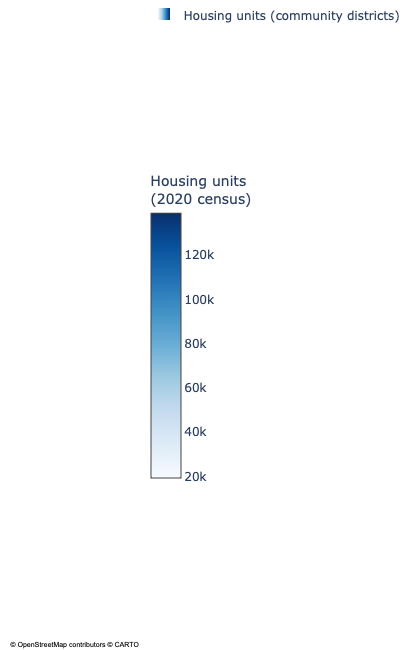

In [21]:
fig = go.Figure(housing_layer)

fig.update_layout(
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},     # the middle of New York City
    map_zoom=9.5,
    height=650,
    margin={"l": 0, "r": 0, "t": 0, "b": 0},
)

fig.show()

In [22]:
zip_edges = go.Choroplethmap(
    geojson=zip_shapes,
    locations=zips["zip"],
    featureidkey="properties.zip",
    z=[0] * len(zips),                        # the same value everywhere: we aren't coloring by a number
    colorscale=[[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]],     # a fully transparent fill...
    showscale=False,                          # no color legend for this layer
    marker_line_color="#555555",              # ...with thin dark gray lines
    marker_line_width=0.6,
    hoverinfo="skip",
    showlegend=True,
    name="ZIP area edges",
)

In [23]:
biggest_bubble = 26                           # the width, in pixels, of the bubble for the most populated area

# the square root of each population, divided by the largest square root, gives a number from 0 to 1.
# Multiply by biggest_bubble for the width in pixels
bubble_sizes = biggest_bubble * (zips["population"] / zips["population"].max()) ** 0.5

# the hover text for each bubble, built the same way, going through three columns at once
bubble_hover = []

for names, neighborhood, population in zip(zips["zip_codes"], zips["neighborhood"], zips["population"]):
    bubble_hover.append(f"<b>{names}</b><br>{neighborhood}<br>Population: {population}")

population_layer = go.Scattermap(
    lat=zips["lat"],
    lon=zips["lon"],
    mode="markers",
    marker={"size": bubble_sizes, "color": "#e6550d", "opacity": 0.55},      # a see-through orange
    text=bubble_hover,
    hoverinfo="text",
    showlegend=True,
    name="Population (ZIP areas)",
)

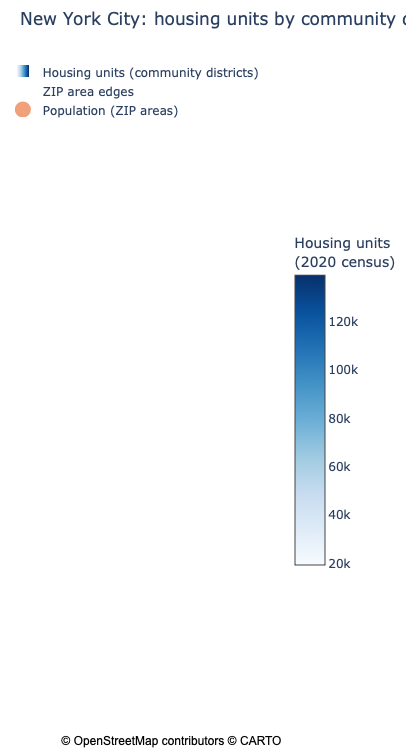

In [24]:
fig = go.Figure([housing_layer, zip_edges, population_layer])

fig.update_layout(
    title="New York City: housing units by community district, and population by ZIP area",
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},
    map_zoom=9.7,
    height=750,
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
    # put the legend in a corner of the map, on a white background
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(255,255,255,0.85)"},
)

fig.show()

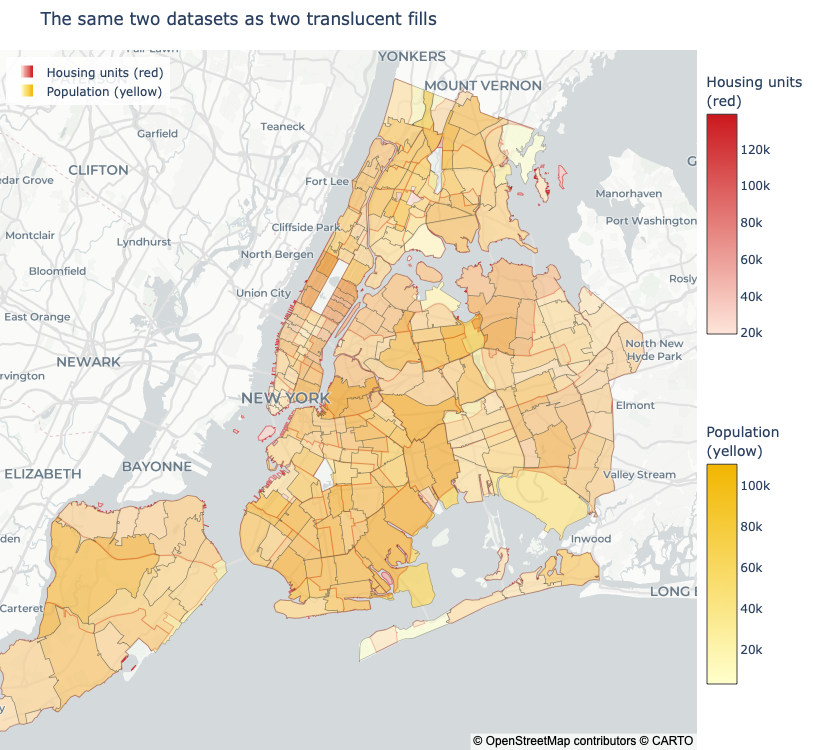

In [25]:
# housing units: community districts in shades of red, 50% see-through
housing_red = go.Choroplethmap(
    geojson=district_shapes,
    locations=districts["commntydst"],
    featureidkey="properties.commntydst",
    z=districts["housing_units"],
    colorscale=[[0, "#fee5d9"], [1, "#cb181d"]],         # from pale red to strong red
    marker_opacity=0.5,
    marker_line_color="#cb181d",
    marker_line_width=1,
    colorbar={"title": "Housing units<br>(red)", "x": 1.0, "y": 0.78, "len": 0.4},
    text=district_hover,
    hoverinfo="text",
    name="Housing units (red)",
    showlegend=True,
)

# population: ZIP areas in shades of yellow, also 50% see-through
population_yellow = go.Choroplethmap(
    geojson=zip_shapes,
    locations=zips["zip"],
    featureidkey="properties.zip",
    z=zips["population"],
    colorscale=[[0, "#ffffcc"], [1, "#f2b600"]],         # from pale yellow to strong yellow
    marker_opacity=0.5,
    marker_line_color="#555555",
    marker_line_width=0.6,
    colorbar={"title": "Population<br>(yellow)", "x": 1.0, "y": 0.28, "len": 0.4},
    text=bubble_hover,                                   # the hover text we made for the bubbles
    hoverinfo="text",
    name="Population (yellow)",
    showlegend=True,
)

fig = go.Figure([housing_red, population_yellow])

fig.update_layout(
    title="The same two datasets as two translucent fills",
    map_style="carto-positron",
    map_center={"lat": 40.71, "lon": -73.95},
    map_zoom=9.7,
    height=750,
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(255,255,255,0.85)"},
)

fig.show()

In [26]:
import pydeck as pdk
from IPython.display import HTML, IFrame